# Candidate-Set Stability: Scoring Only The Categories Not Yet Recorded

This notebook repeats the repeated-split comparison of the source release and the anonymised release `K3_regions` with a scoring rule that matches the task: the next category of a property is always a category that the property has not recorded before the prediction time, so a category that is already recorded can never be the correct answer.

> **Hypothesis test: anonymisation cost (classification).** The publication-readiness audit of the paper points out that the models can rank a category that the property has already recorded, although such a category is never the target. The earlier notebooks score the full ranking of the models. Here every fitted model is scored twice from the same predicted probabilities: once as before (scoring A, all categories) and once with the already-recorded categories removed from the ranking (scoring B, candidate categories only). The question is whether the conclusion of the stability audits, that the difference between the releases cannot be separated from the split-to-split variation, still holds under the stricter scoring.

Nothing is trained differently. The splits, the models, their fixed settings and the preprocessing are those of `02_point_in_time_stability.ipynb`, and scoring A reproduces its results.

## Design

- **Splits.** The same as in the earlier audits. For each of the 50 seeds (1 to 51, without 42) the table is partitioned by two successive grouped shuffle splits by `Customer_ID` (70% train, then the remainder halved into validation and test), using the source customer labels, and the same partitions are applied to both releases. The validation partition is not used.
- **Models.** The Random Forest, the Logistic Regression and CatBoost with the same fixed settings as in the earlier audits, with no search, no tuning and no selection. The preprocessing is fitted on the training partition only.
- **Feature sets.** All six rungs of the feature ladder of notebook 02, with the columns in the order of the modelling table: A (12 documented-record predictors), B (A plus the 8 generalised predictors), C (B plus 17 other static predictors), D (C plus 5 video predictors, 42 in total, the `no_ai` set), D' (D with the video predictors restricted to videos created up to the prediction time) and E (D plus 13 AI predictors, 55 in total, the `full` set).
- **Recorded categories.** For every state, the set of categories that the property has recorded up to the prediction time, `R(t)`. It is read from the documented category counts of the modelling table and checked against the asset table of the workbook.
- **Scoring A (all categories).** As in the earlier notebooks: the predicted class for Top-1 accuracy and the F1 scores, and the ranked probabilities for Top-2 and Top-3.
- **Scoring B (candidate categories only).** The probability of every category in `R(t)` is replaced by a value below every probability, so that these categories rank last. The predicted class is the highest-ranked remaining category, and Top-2 and Top-3 use the highest-ranked remaining categories. The target is never in `R(t)` (checked below), so a removed category is never counted as a correct answer, and when fewer candidates remain than the Top-k asks for, the Top-k contains all of them.
- **Baselines.** The class-prior baseline of the earlier notebooks (scoring A), the same class-prior order with the recorded categories skipped (scoring B), and the expected score of choosing at random among the candidate categories.
- **Descriptive only.** The 50 splits overlap and are drawn from the same 431 states, so the spread is not the sampling variability of a new set of customers, and no significance statement is made.

## Check Against How The Suggestion App Uses The Recommender

The question of this notebook is whether the conclusion of the earlier audits also holds under the way the recommender is used in the front-end application of the project (`my_val_capstone_01`, notification-system branch). The earlier conclusion is that the difference between the anonymised release and the source release cannot be separated from the variation between splits. That conclusion was reached with scoring A, in which the ranking contains all seven categories. The app does not use the ranking in this way.

The app reads the top three categories of the recommender in order and asks the household about the first one that it has not documented yet. It skips a category that is already logged. When all three are logged and another category is still empty, it reads the full ranking and takes the best empty category. The model can name a category that the household already has, because the training does not mask the documented categories, and the documentation of the project says so. The shortlist of the model is therefore a queue that the app reads until it finds a category that is still free. Scoring B (candidates only) describes this situation: the recorded categories are removed from the ranking and the score is computed among the categories that are still free.

Scoring B is a simplified version of the app and not a replay of it. It differs in three ways. It removes the recorded categories from the ranking of all seven categories, whereas the app asks only about the six contents categories and never about Vehicles. It has no step in which an answer changes the household state and the recommender is run again. And its target is the next new category that the property really recorded, whereas the replay of the app counts a suggestion as accepted when the household owns the category at any time in its full record. For this reason the numbers of this notebook are not comparable with the acceptance rate of the replay in the project documentation (64.8% of first suggestions on 71 held-out properties, which is not a model accuracy either).

The publication-readiness audit of the paper makes the same point from the side of the task definition: the target is always a category that the property has not recorded, so the candidate set should be enforced when the model is scored.

## Workflow

The figure shows the notebook. The recorded categories are derived once per state. For each of the 50 seeds every model is fitted once per release and rung, and the same predicted probabilities are scored in two ways. The last step compares the releases under each scoring.

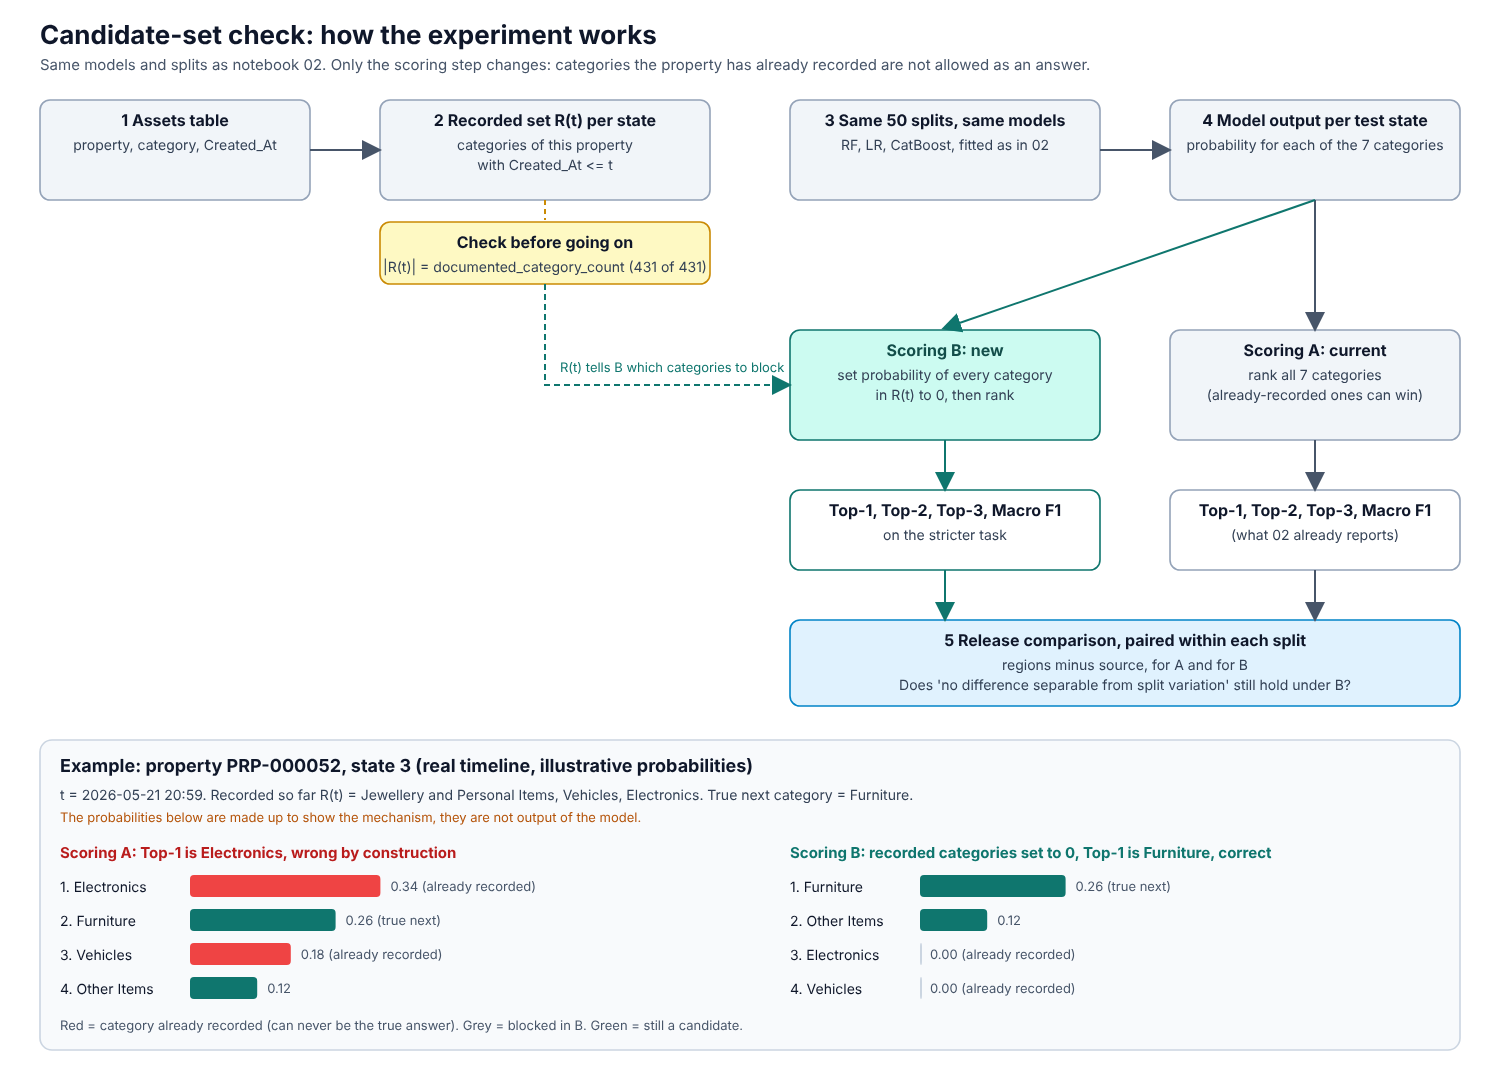

## Setup

The notebook reads the model state tables of the two releases, the asset table of the workbook, which is used to check the recorded categories, and the video table, which is needed to rebuild the video predictors of the rung D'.

In [1]:
# -------------------------------------------------------------------
# Setup
# -------------------------------------------------------------------
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

DATA_DIR = Path("../../../data/processed/hypothesis_testing")
WORKBOOK_PATH = Path("../../../data/raw/Household_Insurance_Synthetic_Dataset_v2_K3_regions.xlsx")

SEEDS = [seed for seed in range(1, 52) if seed != 42]
CHECK_SEED = 42

# Number of splits used by each model. Lower the value of the slowest model (CatBoost) to shorten the run.
N_SPLITS = {"random_forest": 50, "logistic": 50, "catboost": 50}

for path in [DATA_DIR / "source_dataset" / "model_state.csv", DATA_DIR / "regions_anonymised" / "model_state.csv", WORKBOOK_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

## Data

Both modelling tables have the same rows in the same order. The check below confirms that the keys, timestamps and targets are identical in the two releases, so the same row indices can be used for both.

In [2]:
source = pd.read_csv(DATA_DIR / "source_dataset" / "model_state.csv", parse_dates=["Prediction_Time"])
regions = pd.read_csv(DATA_DIR / "regions_anonymised" / "model_state.csv", parse_dates=["Prediction_Time"])

for column in ["Property_ID", "Prediction_Time", "Next_Category"]:
    assert (source[column].values == regions[column].values).all(), column

videos = pd.read_excel(WORKBOOK_PATH, sheet_name="property_videos")
videos["Created_At"] = pd.to_datetime(videos["Created_At"])

RELEASES = {"source": source, "regions": regions}

print("DATA LOADED")
print("-" * 60)
print(f"Rows:       {len(source):,}")
print(f"Properties: {source['Property_ID'].nunique():,}")
print(f"Customers:  {source['Customer_ID'].nunique():,}")
print(f"Videos:     {len(videos):,}")

DATA LOADED
------------------------------------------------------------
Rows:       431
Properties: 234
Customers:  198
Videos:     219


## Recorded Categories Per State

The modelling table holds the number of documented assets per category at the prediction time (`documented_count_CAT-001` to `documented_count_CAT-007`). A category with a count above zero is recorded, which gives the set `R(t)` of every state. Two checks follow. The size of `R(t)` must equal the predictor `documented_category_count`, and the sets must equal the sets that are built independently from the asset table of the workbook (the categories of the assets that the property created up to the prediction time). The target must never be in `R(t)`, because every state ends at a category that is new for the property.

In [3]:
# -------------------------------------------------------------------
# Recorded Categories R(t)
# -------------------------------------------------------------------
CATEGORY_IDS = [f"CAT-00{number}" for number in range(1, 8)]

assets = pd.read_excel(WORKBOOK_PATH, sheet_name="assets", usecols=["Property_ID", "Category_ID", "Category", "Created_At"])
assets["Created_At"] = pd.to_datetime(assets["Created_At"])
CATEGORY_NAME = assets.drop_duplicates("Category_ID").set_index("Category_ID")["Category"].to_dict()
assert set(CATEGORY_IDS) <= set(CATEGORY_NAME), "a category id of the modelling table is missing in the asset table"

CLASSES = sorted(source["Next_Category"].unique())
CLASS_INDEX = {label: position for position, label in enumerate(CLASSES)}
ID_OF_CLASS = {CATEGORY_NAME[category_id]: category_id for category_id in CATEGORY_IDS}

# Recorded categories as a table of rows by classes, in the order of CLASSES.
RECORDED = np.column_stack([(source[f"documented_count_{ID_OF_CLASS[label]}"].values > 0) for label in CLASSES])

print("RECORDED CATEGORIES")
print("-" * 80)
print(f"Categories that occur as a target: {len(CLASSES)} of {len(CATEGORY_IDS)}  {CLASSES}")

# Check 1: the size of R(t) equals the predictor documented_category_count.
all_recorded = np.column_stack([(source[f"documented_count_{category_id}"].values > 0) for category_id in CATEGORY_IDS])
size_ok = (all_recorded.sum(axis=1) == source["documented_category_count"].values)
print(f"States where |R(t)| equals documented_category_count: {int(size_ok.sum())} of {len(source)}")

# Check 2: the sets equal the sets built from the asset table.
pairs = source[["Property_ID", "Prediction_Time"]].reset_index().merge(assets, on="Property_ID")
pairs = pairs[pairs["Created_At"] <= pairs["Prediction_Time"]]
from_assets = pairs.groupby("index")["Category"].agg(set).reindex(source.index)
from_table = pd.Series([{CATEGORY_NAME[category_id] for category_id, flag in zip(CATEGORY_IDS, row) if flag} for row in all_recorded], index=source.index)
set_ok = pd.Series([from_assets.iloc[i] == from_table.iloc[i] for i in range(len(source))])
print(f"States where R(t) equals the set built from the asset table: {int(set_ok.sum())} of {len(source)}")

# Check 3: the target is never recorded.
target_position = source["Next_Category"].map(CLASS_INDEX).values
target_recorded = RECORDED[np.arange(len(source)), target_position]
print(f"States whose target is already in R(t):                {int(target_recorded.sum())} of {len(source)}")

assert size_ok.all(), "R(t) does not match documented_category_count"
assert not target_recorded.any(), "a target is already recorded"

RECORDED CATEGORIES
--------------------------------------------------------------------------------
Categories that occur as a target: 7 of 7  ['Appliances', 'Clothings', 'Electronics', 'Furniture', 'Jewellery and Personal Items', 'Other Items', 'Vehicles']
States where |R(t)| equals documented_category_count: 431 of 431
States where R(t) equals the set built from the asset table: 431 of 431
States whose target is already in R(t):                0 of 431


## Number Of Candidates

The number of candidate categories of a state is the number of categories that occur as a target and are not yet recorded. When at most three candidates remain, the Top-3 contains every candidate and is correct by construction, and when at most two remain the same holds for the Top-2. The table shows how many states are in this situation, which limits how much the Top-2 and Top-3 can tell under scoring B.

In [4]:
recorded_count = RECORDED.sum(axis=1)
candidate_count = len(CLASSES) - recorded_count

counts = pd.DataFrame({"recorded": recorded_count, "candidates": candidate_count})
table = counts.groupby("recorded").agg(states=("candidates", "size"), candidates=("candidates", "first"))
table["share_of_states"] = (table["states"] / len(counts)).map(lambda value: f"{value:.1%}")
table["Top-3 correct by construction"] = table["candidates"] <= 3
table["Top-2 correct by construction"] = table["candidates"] <= 2

print("NUMBER OF RECORDED AND CANDIDATE CATEGORIES PER STATE")
print("-" * 80)
print(table.to_string())
print(f"\nStates with at most 3 candidates (Top-3 correct by construction): {int((candidate_count <= 3).sum())} of {len(counts)} ({(candidate_count <= 3).mean():.1%})")
print(f"States with at most 2 candidates (Top-2 correct by construction): {int((candidate_count <= 2).sum())} of {len(counts)} ({(candidate_count <= 2).mean():.1%})")

NUMBER OF RECORDED AND CANDIDATE CATEGORIES PER STATE
--------------------------------------------------------------------------------
          states  candidates share_of_states  Top-3 correct by construction  Top-2 correct by construction
recorded                                                                                                  
1            170           6           39.4%                          False                          False
2            105           5           24.4%                          False                          False
3             79           4           18.3%                          False                          False
4             56           3           13.0%                           True                          False
5             19           2            4.4%                           True                           True
6              2           1            0.5%                           True                           True

States w

## Video Predictors Restricted To Videos Up To The Prediction Time

The five video predictors of the modelling tables are built from every video of the property, whatever its creation time. The function below rebuilds the same five predictors from the videos created on or before the prediction time, for the rung D'. A state without such a video gets the value zero, no row is removed, and the mean duration is set to zero when there is no video. The first check confirms that the function reproduces the existing columns when every video is used.

In [5]:
# -------------------------------------------------------------------
# Video Predictors With And Without A Time Restriction
# -------------------------------------------------------------------
VIDEO_FEATURES = [
    "video_count",
    "total_video_duration_seconds",
    "mean_video_duration_seconds",
    "total_rooms_covered",
    "total_items_detected",
]


def video_features(frame, up_to_prediction_time):
    pairs = frame[["Property_ID", "Prediction_Time"]].reset_index().merge(videos, on="Property_ID", how="left")
    pairs = pairs[pairs["Video_ID"].notna()]
    if up_to_prediction_time:
        pairs = pairs[pairs["Created_At"] <= pairs["Prediction_Time"]]

    totals = pairs.groupby("index").agg(
        video_count=("Video_ID", "count"),
        total_video_duration_seconds=("Duration_Seconds", "sum"),
        total_rooms_covered=("Rooms_Covered", "sum"),
        total_items_detected=("Items_Detected", "sum"),
    )
    totals = totals.reindex(frame.index).fillna(0.0)
    totals["mean_video_duration_seconds"] = np.where(
        totals["video_count"] > 0, totals["total_video_duration_seconds"] / totals["video_count"].replace(0, np.nan), 0.0
    )
    return totals[VIDEO_FEATURES]


unrestricted = video_features(source, up_to_prediction_time=False)
for column in VIDEO_FEATURES:
    assert np.allclose(unrestricted[column], source[column]), column
print("Rebuilt from all videos, the five video predictors equal the existing columns in all rows.")

restricted = video_features(source, up_to_prediction_time=True)
has_video = source["video_count"] > 0
print(f"\nStates with a video:                         {int(has_video.sum())}")
print(f"States with a video created by t (restricted): {int((restricted['video_count'] > 0).sum())}")
print(f"Rows with at least one value that differs between the two versions: {int((restricted[VIDEO_FEATURES].values != source[VIDEO_FEATURES].values).any(axis=1).sum())} of {len(source)}")

# The restricted columns are added to the modelling tables of both releases under new names.
STRICT_VIDEO_FEATURES = [f"{column}_by_t" for column in VIDEO_FEATURES]
for frame in (source, regions):
    for column, new_column in zip(VIDEO_FEATURES, STRICT_VIDEO_FEATURES):
        frame[new_column] = restricted[column].values

Rebuilt from all videos, the five video predictors equal the existing columns in all rows.

States with a video:                         94
States with a video created by t (restricted): 14
Rows with at least one value that differs between the two versions: 80 of 431


## Feature Sets

The six rungs of the feature ladder of notebook 02, with the same predictors and the same column order as the modelling table. The rung A has the 12 documented-record predictors, and the rungs B, C, D and E add one block each. The rung D' is the rung D with every video predictor replaced by its restricted version in the same position. The rungs A, D and E are the `pure_record`, `no_ai` and `full` feature sets of the modelling notebooks.

In [6]:
# -------------------------------------------------------------------
# Feature Ladder
# -------------------------------------------------------------------
IDENTIFIERS = ["Property_ID", "Customer_ID", "Prediction_Time", "Next_Category_ID", "Next_Category"]

original_columns = [column for column in pd.read_csv(DATA_DIR / "source_dataset" / "model_state.csv", nrows=1).columns]
ALL_FEATURES = [column for column in original_columns if column not in IDENTIFIERS]

RECORD_FEATURES = [
    "documented_asset_count",
    "documented_category_count",
    "documented_value_total",
    "documented_replacement_cost_total",
    "mean_evidence_rating",
] + [f"documented_count_CAT-00{number}" for number in range(1, 8)]

GENERALISED_FEATURES = [
    "Age_Band", "Gender", "State", "Occupation",
    "Property_Type", "Number_Of_Bedrooms", "Number_Of_Occupants", "Property_Valuation_AUD",
]

OTHER_STATIC_FEATURES = [
    "Occupancy_Type", "Is_Home_Insured", "Insurance_Coverage_Type", "Is_Primary",
    "Membership_Level", "Account_Status",
    "Financial_Literacy_Band", "Insurance_Confidence_1_5", "Engagement_Tier", "Preferred_Channel",
    "Preferred_Explanation_Style", "Notification_Opt_In", "Household_Type", "Income_Band",
    "Tenure_Months", "Prior_Claim_Experience", "Underinsurance_Awareness",
]

AI_FEATURES = [column for column in ALL_FEATURES if column.startswith("ai_")]


def in_table_order(columns):
    # The columns keep the order of the modelling table, because the order can change the forest slightly.
    return [column for column in ALL_FEATURES if column in set(columns)]


BLOCKS = {
    "A": RECORD_FEATURES,
    "B": GENERALISED_FEATURES,
    "C": OTHER_STATIC_FEATURES,
    "D": VIDEO_FEATURES,
    "E": AI_FEATURES,
}

FEATURE_SETS = {
    "A": in_table_order(BLOCKS["A"]),
    "B": in_table_order(BLOCKS["A"] + BLOCKS["B"]),
    "C": in_table_order(BLOCKS["A"] + BLOCKS["B"] + BLOCKS["C"]),
    "D": in_table_order(BLOCKS["A"] + BLOCKS["B"] + BLOCKS["C"] + BLOCKS["D"]),
    "E": in_table_order(BLOCKS["A"] + BLOCKS["B"] + BLOCKS["C"] + BLOCKS["D"] + BLOCKS["E"]),
}
FEATURE_SETS["D'"] = [dict(zip(VIDEO_FEATURES, STRICT_VIDEO_FEATURES)).get(column, column) for column in FEATURE_SETS["D"]]
FEATURE_SETS = {rung: FEATURE_SETS[rung] for rung in ["A", "B", "C", "D", "D'", "E"]}

# The ladder must contain every predictor of the earlier audits and nothing else.
assert FEATURE_SETS["E"] == ALL_FEATURES and len(FEATURE_SETS["E"]) == 55
assert FEATURE_SETS["D"] == [c for c in ALL_FEATURES if not c.startswith("ai_")] and len(FEATURE_SETS["D"]) == 42
assert len(FEATURE_SETS["A"]) == 12
for name, columns in FEATURE_SETS.items():
    assert len(columns) == len(set(columns)), name

print("FEATURE LADDER")
print("-" * 60)
for name, columns in FEATURE_SETS.items():
    print(f"{name:<3} {len(columns):>2} predictors")

FEATURE LADDER
------------------------------------------------------------
A   12 predictors
B   20 predictors
C   37 predictors
D   42 predictors
D'  42 predictors
E   55 predictors


## Models And Scoring

The models, the preprocessing and the split function are those of notebook 02. The function `evaluate` fits one model and returns the scores of both scoring rules from the same predicted probabilities. Scoring A is computed exactly as in the earlier notebooks, from the predicted class and from the stable ranking of the probabilities. In scoring B the probability of every recorded category is replaced by -1 before the ranking, so these categories come last, and the predicted class is the first category of the new ranking. The function also reports the share of test states for which the highest-ranked category in scoring A is already recorded, that is the share of states where the model's first choice can never be correct.

In [7]:
# -------------------------------------------------------------------
# Models
# -------------------------------------------------------------------
FOREST_SETTINGS = dict(n_estimators=500, class_weight="balanced_subsample", random_state=42, n_jobs=-1)
LOGISTIC_SETTINGS = dict(max_iter=5000, random_state=42)
CATBOOST_SETTINGS = dict(
    loss_function="MultiClass",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=0,
    allow_writing_files=False,
    thread_count=-1,
)

MODELS = {
    "random_forest": (RandomForestClassifier, FOREST_SETTINGS),
    "logistic": (LogisticRegression, LOGISTIC_SETTINGS),
    "catboost": (CatBoostClassifier, CATBOOST_SETTINGS),
}
MODEL_LABELS = {"random_forest": "Random Forest", "logistic": "Logistic Regression", "catboost": "CatBoost"}


# -------------------------------------------------------------------
# Functions
# -------------------------------------------------------------------
def build_pipeline(frame, columns, model_name="random_forest"):
    numeric = frame[columns].select_dtypes(include=["number"]).columns.tolist()
    categorical = [column for column in columns if column not in numeric]

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numerical",
                Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]),
                numeric,
            ),
            (
                "categorical",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore")),
                ]),
                categorical,
            ),
        ]
    )

    classifier_class, settings = MODELS[model_name]
    return Pipeline([("preprocessor", preprocessor), ("classifier", classifier_class(**settings))])


def customer_grouped_split(seed):
    groups = source["Customer_ID"]
    target = source["Next_Category"]

    train_idx, temp_idx = next(
        GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=seed).split(source, target, groups=groups)
    )
    val_rel, test_rel = next(
        GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=seed).split(
            source.iloc[temp_idx], target.iloc[temp_idx], groups=groups.iloc[temp_idx]
        )
    )
    return train_idx, temp_idx[val_rel], temp_idx[test_rel]


def scores(y_true, predictions, ranked):
    """Top-1 accuracy and F1 from the predicted class, Top-2 and Top-3 from the ranked classes."""
    return dict(
        top1_accuracy=accuracy_score(y_true, predictions),
        macro_f1=f1_score(y_true, predictions, average="macro", zero_division=0),
        weighted_f1=f1_score(y_true, predictions, average="weighted", zero_division=0),
        top2_accuracy=float(np.mean([truth in row[:2] for truth, row in zip(y_true, ranked)])),
        top3_accuracy=float(np.mean([truth in row[:3] for truth, row in zip(y_true, ranked)])),
    )


def evaluate(release, feature_set, train_idx, test_idx, model_name="random_forest"):
    frame = RELEASES[release]
    columns = FEATURE_SETS[feature_set]
    X_train, X_test = frame[columns].iloc[train_idx], frame[columns].iloc[test_idx]
    y_train, y_test = frame["Next_Category"].iloc[train_idx], frame["Next_Category"].iloc[test_idx]

    model = build_pipeline(frame, columns, model_name).fit(X_train, y_train)
    probabilities = model.predict_proba(X_test)
    classes = np.asarray(model.named_steps["classifier"].classes_)
    recorded = RECORDED[test_idx][:, [CLASS_INDEX[label] for label in classes]]

    # Scoring A: all categories, as in the earlier notebooks.
    order_all = np.argsort(-probabilities, axis=1, kind="stable")
    result_all = scores(y_test.values, np.asarray(model.predict(X_test)).ravel(), classes[order_all])

    # Scoring B: the recorded categories rank last.
    order_candidates = np.argsort(-np.where(recorded, -1.0, probabilities), axis=1, kind="stable")
    ranked_candidates = classes[order_candidates]
    result_candidates = scores(y_test.values, ranked_candidates[:, 0], ranked_candidates)

    first_choice_recorded = float(recorded[np.arange(len(test_idx)), order_all[:, 0]].mean())
    return result_all, result_candidates, first_choice_recorded

## Reproduction Check

Before the repetitions, the Random Forest is run on the seed-42 split of the modelling notebooks. In scoring A, the Top-1 metrics of the rungs A, D and E must equal the holdout results saved by the modelling notebooks for both releases, which confirms that the splits, the preprocessing and the predictors are the same as in the earlier notebooks and that scoring A is unchanged. For scoring B the check confirms that no recorded category can be the first choice.

In [8]:
SAVED_FOLDERS = {"A": "03_pure_record", "D": "02_no_ai_features", "E": "01_full_feature_set"}
RELEASE_FOLDERS = {"source": "source_dataset", "regions": "regions_anonymised"}

train_idx, val_idx, test_idx = customer_grouped_split(CHECK_SEED)

print("REPRODUCTION OF THE SEED-42 TOP-1 RESULTS (RANDOM FOREST, SCORING A)")
print("-" * 80)

for release, release_folder in RELEASE_FOLDERS.items():
    for rung, feature_folder in SAVED_FOLDERS.items():
        saved = pd.read_csv(DATA_DIR / release_folder / feature_folder / "results_holdout_test.csv").iloc[0]
        result_all, result_candidates, first_choice_recorded = evaluate(release, rung, train_idx, test_idx, "random_forest")

        difference = max(
            abs(result_all["top1_accuracy"] - saved["Top1_Accuracy"]),
            abs(result_all["macro_f1"] - saved["Top1_Macro_F1"]),
            abs(result_all["weighted_f1"] - saved["Top1_Weighted_F1"]),
        )
        print(
            f"{release:<8} rung {rung}  A: accuracy {result_all['top1_accuracy']:.4f} | max difference to saved {difference:.2e}"
            f"  ||  B: accuracy {result_candidates['top1_accuracy']:.4f} | first choice recorded in A: {first_choice_recorded:.1%}"
        )
        assert difference < 1e-9, (release, rung)

print("\nThe rungs A, D and E reproduce the saved holdout results in scoring A.")

REPRODUCTION OF THE SEED-42 TOP-1 RESULTS (RANDOM FOREST, SCORING A)
--------------------------------------------------------------------------------
source   rung A  A: accuracy 0.4576 | max difference to saved 0.00e+00  ||  B: accuracy 0.4576 | first choice recorded in A: 0.0%
source   rung D  A: accuracy 0.5424 | max difference to saved 5.55e-17  ||  B: accuracy 0.5424 | first choice recorded in A: 0.0%
source   rung E  A: accuracy 0.4915 | max difference to saved 5.55e-17  ||  B: accuracy 0.4915 | first choice recorded in A: 0.0%
regions  rung A  A: accuracy 0.4576 | max difference to saved 0.00e+00  ||  B: accuracy 0.4576 | first choice recorded in A: 0.0%
regions  rung D  A: accuracy 0.4915 | max difference to saved 5.55e-17  ||  B: accuracy 0.5085 | first choice recorded in A: 1.7%
regions  rung E  A: accuracy 0.4915 | max difference to saved 5.55e-17  ||  B: accuracy 0.4915 | first choice recorded in A: 0.0%

The rungs A, D and E reproduce the saved holdout results in scoring A

## Baselines

Three reference values are computed for every split. The class-prior baseline of the earlier notebooks always ranks the categories by their frequency in the training partition (scoring A). The same ranking with the recorded categories skipped is the baseline of scoring B, and its Top-1 is the most frequent training category that is not yet recorded. The third reference is the expected score of choosing at random among the candidate categories of every state, which is `min(k, c) / c` for `c` candidates, and it has no F1 score.

In [9]:
# -------------------------------------------------------------------
# Baselines
# -------------------------------------------------------------------
def baselines_for_split(train_idx, test_idx):
    y_train = source["Next_Category"].iloc[train_idx]
    y_test = source["Next_Category"].iloc[test_idx].values
    recorded = RECORDED[test_idx]

    counts = y_train.value_counts()
    order = sorted(counts.index, key=lambda label: (-counts[label], label))

    ranked_all = [order for _ in y_test]
    ranked_candidates = [[label for label in order if not recorded[row, CLASS_INDEX[label]]] for row in range(len(y_test))]

    result_all = scores(y_test, np.repeat(order[0], len(y_test)), ranked_all)
    result_candidates = scores(y_test, [row[0] if row else "none" for row in ranked_candidates], ranked_candidates)

    candidates = len(CLASSES) - recorded.sum(axis=1)
    result_random = dict(
        top1_accuracy=float(np.mean(1.0 / candidates)),
        top2_accuracy=float(np.mean(np.minimum(2, candidates) / candidates)),
        top3_accuracy=float(np.mean(np.minimum(3, candidates) / candidates)),
        macro_f1=np.nan,
        weighted_f1=np.nan,
    )
    return result_all, result_candidates, result_random


rows = []
for seed in SEEDS:
    train_idx, val_idx, test_idx = customer_grouped_split(seed)
    for name, result in zip(["class prior, all categories", "class prior, candidates only", "random among candidates"], baselines_for_split(train_idx, test_idx)):
        rows.append(dict(seed=seed, baseline=name, **result))
baseline_per_split = pd.DataFrame(rows)

print("BASELINES (mean over the splits)")
print("-" * 80)
print(baseline_per_split.drop(columns="seed").groupby("baseline").mean().round(4).to_string())

BASELINES (mean over the splits)
--------------------------------------------------------------------------------
                              top1_accuracy  macro_f1  weighted_f1  top2_accuracy  top3_accuracy
baseline                                                                                        
class prior, all categories          0.1977    0.0487       0.0666         0.3945         0.5711
class prior, candidates only         0.3622    0.2662       0.2986         0.6693         0.8768
random among candidates              0.2298       NaN          NaN         0.4557         0.6586


## Repeated Splits

For each seed the models are refitted on the training partition and scored on the test partition, for both releases and all six rungs. Every fit gives one row for scoring A and one row for scoring B. Nothing is tuned or selected on any split. The run times of the three models differ strongly, and the number of splits of each model is set by `N_SPLITS` in the setup cell.

In [10]:
records = []


def run_model(model_name):
    started = time.time()
    seeds = SEEDS[: N_SPLITS[model_name]]

    for number, seed in enumerate(seeds, start=1):
        train_idx, val_idx, test_idx = customer_grouped_split(seed)

        for release in RELEASES:
            for feature_set in FEATURE_SETS:
                result_all, result_candidates, first_choice_recorded = evaluate(release, feature_set, train_idx, test_idx, model_name)
                common = dict(seed=seed, model=model_name, release=release, feature_set=feature_set, test_rows=len(test_idx), first_choice_recorded=first_choice_recorded)
                records.append(dict(scoring="A: all categories", **common, **result_all))
                records.append(dict(scoring="B: candidates only", **common, **result_candidates))

        if number % 10 == 0:
            print(f"{MODEL_LABELS[model_name]}: {number} of {len(seeds)} splits done ({(time.time() - started) / 60:.1f} min)")

    print(f"{MODEL_LABELS[model_name]} finished: {len(seeds)} splits in {(time.time() - started) / 60:.1f} min")

In [11]:
run_model("random_forest")

Random Forest: 10 of 50 splits done (1.9 min)
Random Forest: 20 of 50 splits done (3.7 min)
Random Forest: 30 of 50 splits done (5.2 min)
Random Forest: 40 of 50 splits done (6.6 min)
Random Forest: 50 of 50 splits done (8.0 min)
Random Forest finished: 50 splits in 8.0 min


In [12]:
run_model("logistic")

Logistic Regression: 10 of 50 splits done (0.1 min)
Logistic Regression: 20 of 50 splits done (0.1 min)
Logistic Regression: 30 of 50 splits done (0.2 min)
Logistic Regression: 40 of 50 splits done (0.3 min)
Logistic Regression: 50 of 50 splits done (0.4 min)
Logistic Regression finished: 50 splits in 0.4 min


In [13]:
run_model("catboost")

CatBoost: 10 of 50 splits done (11.3 min)
CatBoost: 20 of 50 splits done (23.0 min)
CatBoost: 30 of 50 splits done (36.6 min)
CatBoost: 40 of 50 splits done (50.6 min)
CatBoost: 50 of 50 splits done (76.9 min)
CatBoost finished: 50 splits in 76.9 min


## Spread Of Each Cell Under Both Scorings

Mean and standard deviation of every metric over the splits of each model, for each scoring, release and rung. The baselines are shown after the last model: they do not depend on the model or on the release.

In [14]:
per_split = pd.DataFrame(records)
METRICS = {
    "top1_accuracy": "Top-1",
    "top2_accuracy": "Top-2",
    "top3_accuracy": "Top-3",
    "macro_f1": "Macro F1",
    "weighted_f1": "Weighted F1",
}
RUNGS = list(FEATURE_SETS)
SCORINGS = ["A: all categories", "B: candidates only"]

for model_name in [m for m in MODELS if m in set(per_split["model"])]:
    group = per_split[per_split["model"] == model_name]
    print("=" * 110)
    print(f"{MODEL_LABELS[model_name]}: {group['seed'].nunique()} splits")
    print("=" * 110)

    table = []
    for scoring in SCORINGS:
        for release in RELEASES:
            for rung in RUNGS:
                part = group[(group["scoring"] == scoring) & (group["release"] == release) & (group["feature_set"] == rung)]
                row = {"scoring": scoring, "release": release, "rung": rung}
                for column, label in METRICS.items():
                    row[label] = f"{part[column].mean():.4f} ({part[column].std():.4f})"
                table.append(row)
    print("mean (standard deviation) over the splits")
    print(pd.DataFrame(table).to_string(index=False))
    print()

print("=" * 110)
print("Baselines (all models and releases)")
print("=" * 110)
table = []
for name, part in baseline_per_split.groupby("baseline"):
    row = {"baseline": name}
    for column, label in METRICS.items():
        row[label] = "-" if part[column].isna().all() else f"{part[column].mean():.4f} ({part[column].std():.4f})"
    table.append(row)
print(pd.DataFrame(table).to_string(index=False))

Random Forest: 50 splits
mean (standard deviation) over the splits
           scoring release rung           Top-1           Top-2           Top-3        Macro F1     Weighted F1
 A: all categories  source    A 0.4038 (0.0462) 0.6766 (0.0462) 0.8181 (0.0372) 0.3252 (0.0518) 0.3901 (0.0448)
 A: all categories  source    B 0.4626 (0.0548) 0.7403 (0.0452) 0.8639 (0.0362) 0.3709 (0.0638) 0.4278 (0.0540)
 A: all categories  source    C 0.4658 (0.0456) 0.7319 (0.0463) 0.8566 (0.0374) 0.3617 (0.0525) 0.4265 (0.0489)
 A: all categories  source    D 0.4752 (0.0440) 0.7301 (0.0492) 0.8514 (0.0404) 0.3780 (0.0582) 0.4369 (0.0478)
 A: all categories  source   D' 0.4746 (0.0537) 0.7395 (0.0476) 0.8573 (0.0394) 0.3699 (0.0587) 0.4331 (0.0575)
 A: all categories  source    E 0.4590 (0.0470) 0.7150 (0.0499) 0.8468 (0.0360) 0.3506 (0.0543) 0.4148 (0.0499)
 A: all categories regions    A 0.4038 (0.0462) 0.6766 (0.0462) 0.8181 (0.0372) 0.3252 (0.0518) 0.3901 (0.0448)
 A: all categories regions    B 0.459

## Effect Of The Anonymisation Under Each Scoring

For every split the score of the source release is subtracted from the score of the anonymised release, separately for each scoring, so a negative difference means that the anonymised release is worse. The columns give the mean, the standard deviation, the 2.5th and 97.5th percentiles of the differences over the splits, the share of splits with a negative difference and the share with a difference of exactly zero. The comparison to make is whether the differences under scoring B are of the same size as under scoring A and as the split-to-split variation.

In [15]:
def describe(values):
    values = np.asarray(values, dtype=float)
    return dict(
        mean=values.mean(),
        sd=values.std(ddof=1) if len(values) > 1 else np.nan,
        p2_5=np.percentile(values, 2.5),
        p97_5=np.percentile(values, 97.5),
        below_zero=(values < 0).mean(),
        zero=(values == 0).mean(),
    )


def wide(model_name, column):
    part = per_split[per_split["model"] == model_name]
    return part.pivot_table(index="seed", columns=["scoring", "release", "feature_set"], values=column)


def format_table(rows):
    frame = pd.DataFrame(rows)
    for column in ["mean", "sd", "p2_5", "p97_5"]:
        frame[column] = frame[column].map(lambda value: f"{value:+.4f}")
    for column in ["below_zero", "zero"]:
        frame[column] = frame[column].map(lambda value: f"{value:.0%}")
    return frame.to_string(index=False)


for model_name in [m for m in MODELS if m in set(per_split["model"])]:
    print("=" * 110)
    print(f"{MODEL_LABELS[model_name]}: anonymised release minus source release, paired within each split")
    print("=" * 110)

    rows = []
    for column, label in METRICS.items():
        table = wide(model_name, column)
        for scoring in SCORINGS:
            for rung in RUNGS:
                difference = table[(scoring, "regions", rung)] - table[(scoring, "source", rung)]
                rows.append(dict(metric=label, scoring=scoring[:1], rung=rung, **describe(difference)))
    print(format_table(rows))
    print()

Random Forest: anonymised release minus source release, paired within each split
     metric scoring rung    mean      sd    p2_5   p97_5 below_zero zero
      Top-1       A    A +0.0000 +0.0000 +0.0000 +0.0000         0% 100%
      Top-1       A    B -0.0026 +0.0421 -0.0916 +0.0609        36%  14%
      Top-1       A    C +0.0039 +0.0329 -0.0553 +0.0662        36%  18%
      Top-1       A    D +0.0093 +0.0287 -0.0357 +0.0552        30%  16%
      Top-1       A   D' -0.0069 +0.0332 -0.0710 +0.0433        44%  22%
      Top-1       A    E +0.0006 +0.0307 -0.0563 +0.0543        40%  12%
      Top-1       B    A +0.0000 +0.0000 +0.0000 +0.0000         0% 100%
      Top-1       B    B -0.0007 +0.0413 -0.0916 +0.0583        34%  14%
      Top-1       B    C +0.0012 +0.0304 -0.0557 +0.0662        38%  14%
      Top-1       B    D +0.0103 +0.0309 -0.0435 +0.0581        34%   8%
      Top-1       B   D' -0.0092 +0.0301 -0.0655 +0.0395        50%  16%
      Top-1       B    E -0.0024 +0.0315 -0

## What The Stricter Scoring Changes

For every split the score under scoring A is subtracted from the score under scoring B for the same fitted model, so a positive value means that removing the recorded categories raises the score. This is the effect of the scoring rule alone, since the models and the predicted probabilities are identical. The table also gives, for each model, release and rung, the share of test states for which the highest-ranked category of scoring A is already recorded, that is the share of first choices that could never be correct.

In [16]:
for model_name in [m for m in MODELS if m in set(per_split["model"])]:
    for release in RELEASES:
        print("=" * 110)
        print(f"{MODEL_LABELS[model_name]}, {release} release: scoring B minus scoring A")
        print("=" * 110)

        rows = []
        for column, label in METRICS.items():
            table = wide(model_name, column)
            for rung in RUNGS:
                difference = table[(SCORINGS[1], release, rung)] - table[(SCORINGS[0], release, rung)]
                rows.append(dict(metric=label, rung=rung, **describe(difference)))
        print(format_table(rows))
        print()

print("=" * 110)
print("Share of test states whose highest-ranked category in scoring A is already recorded (mean and standard deviation over the splits)")
print("=" * 110)
part = per_split[per_split["scoring"] == SCORINGS[0]]
table = part.groupby(["model", "release", "feature_set"])["first_choice_recorded"].agg(["mean", "std"])
table["share"] = table.apply(lambda row: f"{row['mean']:.1%} ({row['std']:.1%})", axis=1)
print(table[["share"]].to_string())

Random Forest, source release: scoring B minus scoring A
     metric rung    mean      sd    p2_5   p97_5 below_zero zero
      Top-1    A +0.0074 +0.0112 +0.0000 +0.0363         0%  64%
      Top-1    B +0.0112 +0.0136 +0.0000 +0.0370         0%  52%
      Top-1    C +0.0169 +0.0185 +0.0000 +0.0595         0%  38%
      Top-1    D +0.0143 +0.0187 +0.0000 +0.0597         0%  50%
      Top-1   D' +0.0166 +0.0189 +0.0000 +0.0589         0%  46%
      Top-1    E +0.0255 +0.0205 +0.0000 +0.0669         0%  24%
      Top-2    A +0.0217 +0.0202 +0.0000 +0.0625         0%  26%
      Top-2    B +0.0290 +0.0206 +0.0000 +0.0657         0%  18%
      Top-2    C +0.0476 +0.0312 +0.0000 +0.1145         0%  10%
      Top-2    D +0.0462 +0.0294 +0.0000 +0.1134         0%   8%
      Top-2   D' +0.0396 +0.0284 +0.0000 +0.1007         0%  10%
      Top-2    E +0.0566 +0.0269 +0.0144 +0.1097         0%   2%
      Top-3    A +0.0412 +0.0280 +0.0000 +0.1040         0%  10%
      Top-3    B +0.0549 +0.0303 

## Results And Interpretation

All statements are descriptive. The 50 splits overlap and come from the same 431 states, so the spreads are not the sampling variability of a new set of customers, and no significance is claimed. "Anonymised minus source" means the score of the anonymised release minus the score of the source release within each split.

**Checks.** The recorded categories agree with the documented counts in 431 of 431 states and with the asset table in 431 of 431 states, and the target is never one of them (0 of 431). The rungs A, D and E of the Random Forest reproduce the saved seed-42 results of the earlier notebooks in scoring A (largest difference 5.6e-17). In scoring B, 77 of 431 states (17.9%) have at most three candidates, so Top-3 is correct there by construction, and 21 of 431 (4.9%) have at most two candidates, so Top-2 is correct by construction. Part of the gain of Top-3 under scoring B therefore comes from the shortened list and not from the model.

**Baselines.** In scoring A the class prior reaches Top-1 0.198, Top-2 0.395 and Top-3 0.571. When the recorded categories are skipped, the same class prior reaches 0.362, 0.669 and 0.877, and choosing at random among the candidates reaches 0.230, 0.456 and 0.659. Skipping the recorded categories alone lifts the weakest reference a long way, so the candidate-only scores of the models should be read against 0.362 / 0.669 / 0.877 and not against the scoring A reference. Under scoring B the Random Forest and CatBoost are above this prior in Top-1 from rung B upward (about 0.46 to 0.50 against 0.36). In Top-3 the prior is already 0.877, and the models are between 0.90 and 0.92, so the margin there is small. The Logistic Regression is below the prior in Top-1 from rung B upward (0.35 to 0.40).

**What the stricter scoring changes.** Scoring B can only help or leave a score unchanged, and this is what the tables show (the share of splits below zero is 0% for almost every cell). The size of the change depends on the model and on how often the model ranks a recorded category first. For the Random Forest the share of test states whose first choice is a recorded category is 0.7% to 3.7%, and Top-1 rises by about 0.7 to 2.6 points and Top-3 by about 4 to 7 points. For the Logistic Regression the share is 1.7% at rung A and 4% to 13% from rung B upward, and Top-1 rises by up to 5.3 points and Top-3 by up to 12.9 points, which is the largest change of the three models. For CatBoost the share is at most 0.1%, Top-1 does not change (0.0 to 0.1 points) and Top-3 rises by about 1 to 1.5 points. The Logistic Regression at rung A is the best model in Top-1 in both scorings (0.462 in scoring A, 0.473 in scoring B), and it falls behind the Random Forest and CatBoost as soon as predictors are added, in both scorings.

**The difference between the releases under scoring B.** The mean difference (anonymised minus source) stays small and changes sign between cells. Under scoring B the mean differences of Top-1 lie between -0.9 and +1.0 points for the Random Forest, between -0.7 and +1.0 points for the Logistic Regression and between -0.9 and +0.5 points for CatBoost. For Top-3 they lie between -1.5 and +0.1 points, between -0.1 and +0.7 points, and between -0.8 and 0.0 points. For Macro F1 they lie between -1.2 and +1.1, between -0.8 and +0.5, and between -0.6 and +1.2 points. The standard deviation of the paired difference is larger than the mean in every cell (about 3 to 6 points in Top-1, 2 to 4 points in Top-3, 3 to 6 points in Macro F1), and the 2.5% to 97.5% interval of the difference contains zero in almost every cell. The largest positive differences under scoring A (Logistic Regression, rung B, Top-1 +2.5 and Top-2 +3.7 points) shrink to +1.0 and +1.9 points under scoring B. The largest Top-3 difference under scoring B, Random Forest at rung B (-1.5 points, 64% of the splits below zero), is the cell with the most consistent sign across splits, and it is a small difference against a split spread of 2 points.

**Reading.** This notebook is a robustness check of the earlier conclusion under the way the suggestion app uses the recommender. The conclusion holds: the difference between the releases is still smaller than the variation between splits, and the two cannot be separated. The mean difference does not point in one direction across rungs and models, which is a statement about what the 50 splits can and cannot separate, not a proof that the anonymisation has no effect and not a statement that the two releases are equal. The scoring also does not change which feature groups matter: the gain from rung A to rung B remains the largest step for the Random Forest and CatBoost and reverses for the Logistic Regression, and video and AI predictors add nothing that is visible against the spread.

**Use of the numbers.** The scores of this notebook are not an estimate of the effect of the app, and they are not to be compared with the acceptance rate of the app replay in the project documentation (64.8% of first suggestions on 71 held-out properties).

**Limits.** Scoring B is a simplified version of the app (all seven categories, no state-update loop, target is the next new category), so these numbers are not an estimate of the acceptance rate of the app. The static attributes have no timestamp and are assumed to equal their value at the prediction time, which applies to both scorings and both releases. The test partitions have 52 to 83 rows, and 17.9% of the states have so few candidates that Top-3 is correct by construction, which weakens the Top-3 comparison under scoring B in particular.